## Tarefa 1

O que é esperado encontrar nesse notebook
1. Uso do dataset MNIST
2. Implementação de uma NN
3. Implementação de uma CNN
4. Comparar resultados da NN com a CNN com um número comparável de parâmetros
5. Testar em outros datasets como por exemplo CIFAR 10
6. Modificar imagens - manter tamanho 28x28 mas reduzir reduzir escala e/ou deslocar e/ou adicionar ruido e/ou borrar imagem
7. Utilizar uma quantidade muito menor de dados por classe (50, 100, 500), ou ainda, utilizar classes bem desbalanceadas no conjunto de treinamento
8. Teste de hiperparâmetros - alterar número de camdas/filtros, tipos de ativação, inicialização de pesos, learning rate, otimizador, batch size, entre outros

In [87]:
# importando pacotes
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset
import torchvision.datasets.mnist as tMNIST
import torchvision.datasets.cifar as tCIFAR
from torchvision import transforms
import matplotlib.pyplot as plt
import torchvision.transforms.functional as torchFunc
import torch.optim as optim
import torchmetrics
import os
import time
from transform_utils import gaussian_noise

## Loading Dataset
This section we'll load the dataset and show an image as example

In [2]:
# Downloading MNIST
dataset = tMNIST.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

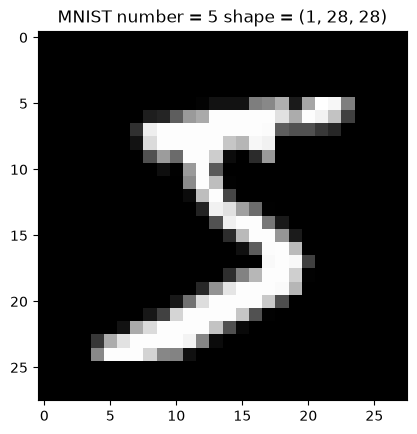

In [3]:
# Showing MNIST dataset
image, target = dataset[0]
input_size_flatten = image.numel()
classes_size = len(dataset.classes)
plt.title(f"MNIST number = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy(), cmap='gray')

In [68]:
print(torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# tamanho de entrada fixo (28x28), cudnn pode escolher o algoritmo de convolução mais rápido
torch.backends.cudnn.benchmark = device.type == "cuda"
print(f"Using device: {device}")

True
Using device: cuda


## Dataset Preparation
Nessa seção iremos realizar a preparação do dataset em treinamento e validação

In [5]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(dataset, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
num_workers = 4 if device.type == "cuda" else 0

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}, Num workers: {num_workers}")


Train size: 42000, Validation size: 9000, Test size: 9000
Batch size: 1024, Pin memory: True, Num workers: 4


In [69]:
def GradientDescent(train_loader, val_loader, model, criteria, optimizer, epochs = 100) -> tuple:
	train_history = []
	val_history = []
	for epoch in range(epochs):
		epoch_start = time.time()
		model.train()
		running_loss = torch.zeros(1, device=device)
		for X, Y in train_loader:
			X = X.to(device, non_blocking=True)
			Y = Y.to(device, non_blocking=True)

			# Forwards pass
			prediction = model(X)
			loss = criteria(prediction, Y)

			# Backward pass
			optimizer.zero_grad(set_to_none=True)
			loss.backward()
			optimizer.step()
			
			running_loss += loss.detach() * X.size(0)
		epoch_loss = running_loss.item() / len(train_loader.dataset)
		train_history.append(epoch_loss)

		model.eval()
		running_val_loss = torch.zeros(1, device=device)
		with torch.no_grad():
			for X, Y in val_loader:
				X = X.to(device, non_blocking=True)
				Y = Y.to(device, non_blocking=True)

				output = model(X)
				loss = criteria(output, Y)
				running_val_loss += loss.detach() * X.size(0)
			epoch_val_loss = running_val_loss.item() / len(val_loader.dataset)
			val_history.append(epoch_val_loss)
		print(f"Epoch {epoch + 1}/{epochs} - train_loss: {epoch_loss:.4f} - val_loss: {epoch_val_loss:.4f} - {time.time() - epoch_start:.1f}s")

	return train_history, val_history

In [70]:
def PlotLoss(history, val_history, model):
	plt.plot(range(1, len(history) + 1), history, label="Train Loss")
	plt.plot(range(1, len(val_history) + 1), val_history, label="Validation Loss")
	trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
	plt.xlabel("Epoch")
	plt.ylabel("Loss")
	plt.title(f"Training and Validation Loss. Number of params = {trainable_params}")
	plt.legend()
	plt.show()

    

In [71]:
def Evaluate(test_loader, classes_size, model):
	accuracy_metric = torchmetrics.Accuracy(task='multiclass', num_classes=classes_size).to(device)
	f1_metric = torchmetrics.F1Score(task='multiclass', num_classes=classes_size).to(device)
	confusion_matrix = torchmetrics.ConfusionMatrix(task='multiclass', num_classes=classes_size).to(device)
	precision = torchmetrics.Precision(task='multiclass', num_classes=classes_size).to(device)
	recall = torchmetrics.Recall(task='multiclass', num_classes=classes_size).to(device)
	specificity = torchmetrics.Specificity(task='multiclass', num_classes=classes_size).to(device)
	auc_roc = torchmetrics.AUROC(task='multiclass', num_classes=classes_size).to(device)
    
	model.eval()
	with torch.no_grad():
		for X, Y in test_loader:
			X = X.to(device, non_blocking=True)
			Y = Y.to(device, non_blocking=True)

			output = model(X)
			probs = torch.softmax(output, dim=1)
			pred = torch.argmax(output, dim=1)
			accuracy_metric.update(pred, Y)
			f1_metric.update(pred, Y)
			confusion_matrix.update(pred, Y)
			precision.update(pred, Y)
			recall.update(pred, Y)
			specificity.update(pred, Y)
			auc_roc.update(probs, Y)

	return accuracy_metric, \
		f1_metric, \
		confusion_matrix, \
		precision, \
		recall, \
		specificity, \
		auc_roc, \
    

In [72]:
def PrintPlotMetrics(test_loader, class_size, model):
	accuracy, f1, confusion, precision, recall, specificity, auc = Evaluate(test_loader, classes_size, model)
	print(f"Accuracy: {accuracy.compute()}")
	print(f"F1: {f1.compute()}")
	print(f"Confusion: {confusion.compute()}")
	print(f"Precision: {precision.compute()}")
	print(f"Recall: {recall.compute()}")
	print(f"Specificity: {specificity.compute()}")
	print(f"AUC: {auc.compute()}")

	confusion.plot()
	plt.show()

## Definindo rede neural
Nesta seção estamos criando uma rede neural

In [10]:
class NeuralNetwork(nn.Module):
	def __init__(self, inputSize, classes_size) -> None:
		super(NeuralNetwork, self).__init__()
		self.network = nn.Sequential(
			nn.Linear(inputSize, 256),
			nn.ReLU(), # Activation
			nn.Linear(256, 64),
			nn.ReLU(), # Activation
			nn.Linear(64, classes_size),
			# CrossEntropyLoss already applies log_softmax internally, so no Softmax here
		)
		# TODO: add dropout

	def forward(self, x):
		x = torch.flatten(x, start_dim=1)
		return self.network(x)


In [11]:
class ConvolutionNeuralNetwork(nn.Module):
	def __init__(self, inputSize, classes_size) -> None:
		super(ConvolutionNeuralNetwork, self).__init__()
		self.backbone = nn.Sequential(
			nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
			nn.ReLU(),
			nn.MaxPool2d(kernel_size=2, stride=2),
			nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
			nn.ReLU(),
			nn.MaxPool2d(kernel_size=2, stride=2)
			# CrossEntropyLoss already applies log_softmax internally, so no Softmax here
		)
		head_input_size = int(32 * inputSize * (0.5 ** 4))
		self.head = nn.Sequential(
			nn.Flatten(),
			nn.Linear(head_input_size, 128),
			nn.ReLU(),
			nn.Linear(128, classes_size)
		)
		

	def forward(self, x):
		x = self.backbone(x)
		x = self.head(x)
		return x


In [12]:
model = NeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [13]:
history, val_history = GradientDescent(train_loader, val_loader, model, criteria, optimizer, epochs=100)

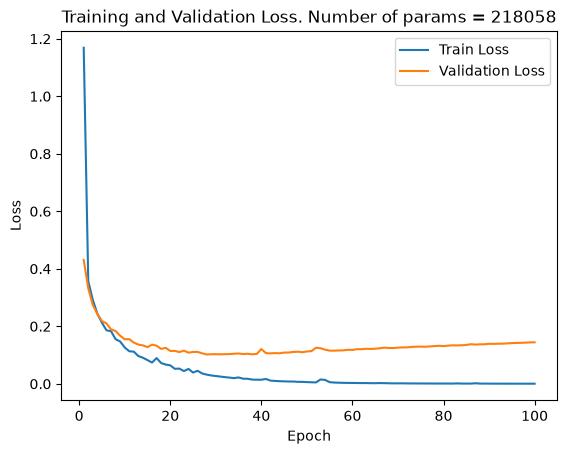

In [14]:
PlotLoss(history, val_history, model)

Accuracy: 0.9783333539962769
F1: 0.9783333539962769
Confusion: tensor([[ 892,    0,    3,    3,    0,    3,    1,    3,    1,    1],
        [   0, 1006,    2,    0,    2,    0,    0,    2,    0,    0],
        [   1,    3,  889,    1,    1,    0,    2,    3,    7,    1],
        [   0,    0,    5,  918,    0,   13,    0,    5,    8,    8],
        [   0,    0,    2,    0,  859,    0,    3,    1,    0,    7],
        [   1,    0,    2,    8,    1,  807,    4,    0,    1,    6],
        [   2,    1,    2,    0,    2,    1,  880,    0,    0,    0],
        [   0,    1,    4,    0,    7,    1,    0,  857,    1,    5],
        [   3,    3,    2,    5,    2,    4,    0,    0,  831,    2],
        [   2,    0,    1,    2,    8,    5,    0,    7,    7,  866]],
       device='cuda:0')
Precision: 0.9783333539962769
Recall: 0.9783333539962769
Specificity: 0.997592568397522
AUC: 0.99927818775177


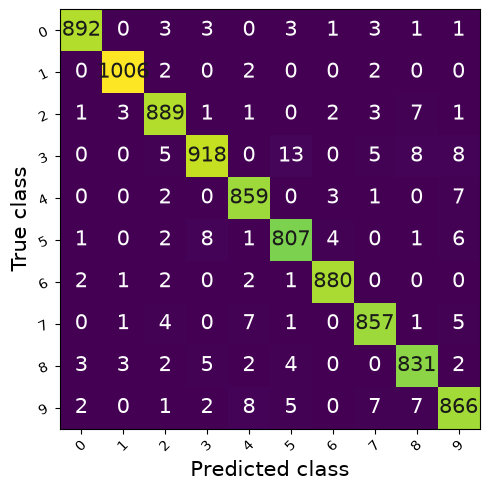

In [15]:
PrintPlotMetrics(test_loader, classes_size, model)

In [16]:
modelCNN = ConvolutionNeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCNN.parameters(), lr=learning_rate)

In [17]:
historyCNN, val_historyCNN = GradientDescent(train_loader, val_loader, modelCNN, criteria, optimizer, epochs=100)

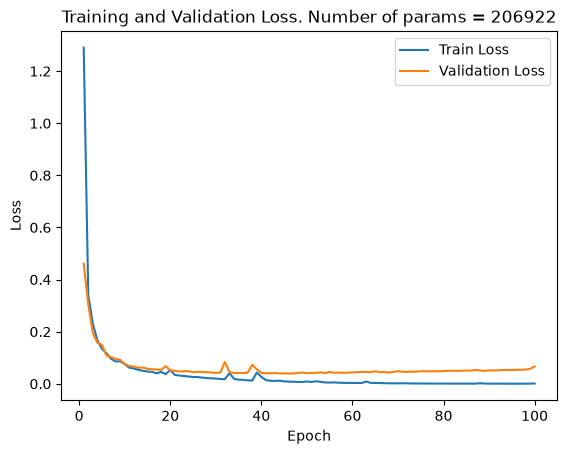

In [18]:
PlotLoss(historyCNN, val_historyCNN, modelCNN)

Accuracy: 0.9856666922569275
F1: 0.9856666922569275
Confusion: tensor([[892,   0,   1,   0,   0,   1,  11,   0,   2,   0],
        [  0, 998,   2,   0,   2,   0,   3,   6,   1,   0],
        [  0,   1, 898,   0,   0,   0,   1,   5,   3,   0],
        [  0,   0,   2, 946,   0,   4,   1,   1,   0,   3],
        [  0,   0,   0,   0, 865,   0,   2,   0,   0,   5],
        [  1,   0,   0,   3,   1, 810,  11,   0,   3,   1],
        [  1,   0,   0,   0,   0,   1, 885,   0,   1,   0],
        [  1,   0,   5,   1,   1,   0,   0, 864,   0,   4],
        [  4,   1,   3,   3,   1,   2,   3,   0, 831,   4],
        [  3,   0,   1,   2,   2,   1,   0,   2,   5, 882]], device='cuda:0')
Precision: 0.9856666922569275
Recall: 0.9856666922569275
Specificity: 0.9984074234962463
AUC: 0.9998898506164551


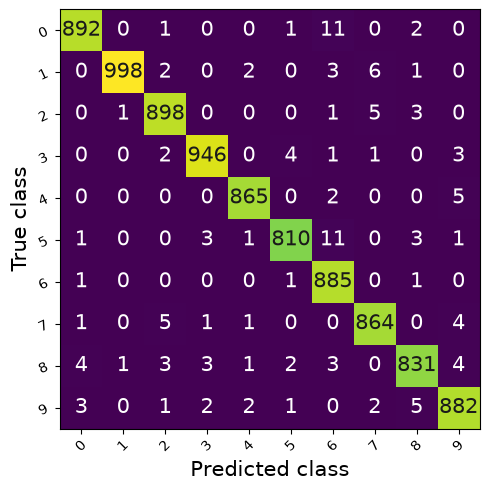

In [19]:
PrintPlotMetrics(test_loader, classes_size, modelCNN)

## Exploração adicional
Aqui iremos realizar as explorações adicionais

#### Utilizando dataset CIFAR 10

In [20]:
# Downloading MNIST
datasetCIFAR = tCIFAR.CIFAR10(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

(50000, 32, 32, 3)


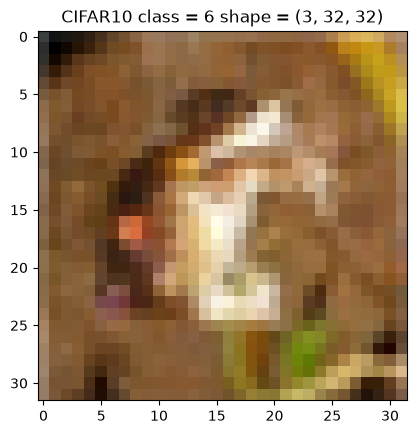

In [21]:
# Showing MNIST dataset
image, target = datasetCIFAR[0]

print(datasetCIFAR.data.shape)
input_size_flatten = image.numel()
classes_size = len(datasetCIFAR.classes)
plt.title(f"CIFAR10 class = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy().T, cmap='gray')

In [22]:
gray_scale_weights = [0.2989, 0.5870, 0.1140]
gray_images = np.dot(datasetCIFAR.data, gray_scale_weights).astype(np.uint8)
datasetCIFAR.data = gray_images

image, _ = datasetCIFAR[0]
input_size_flatten = image.numel()

print(datasetCIFAR.data.shape)
print(f"Model input shape: {tuple(image.shape)}, flattened size: {input_size_flatten}")

(50000, 32, 32)
Model input shape: (1, 32, 32), flattened size: 1024


In [23]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(datasetCIFAR, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
num_workers = 4 if device.type == "cuda" else 0

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}, Num workers: {num_workers}")


Train size: 35000, Validation size: 7500, Test size: 7500
Batch size: 1024, Pin memory: True, Num workers: 4


In [24]:
modelCIFAR = NeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCIFAR.parameters(), lr=learning_rate)

In [25]:
history, val_history = GradientDescent(train_loader, val_loader, modelCIFAR, criteria, optimizer, epochs=100)


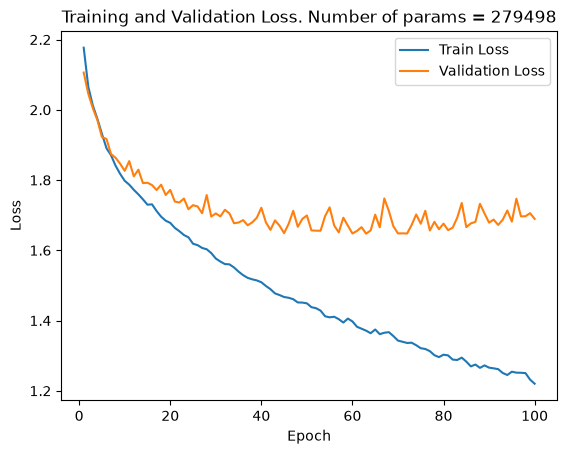

In [26]:
PlotLoss(history, val_history, modelCIFAR)

Accuracy: 0.4244000017642975
F1: 0.4244000017642975
Confusion: tensor([[233,  59,  89,  29,  90,  14,  76,  31, 134,  26],
        [ 19, 433,   9,  24,  32,  11,  64,  21,  73,  93],
        [ 36,  18, 235,  82, 130,  46, 130,  36,  32,   7],
        [ 16,  25,  53, 248,  63,  88, 138,  32,  48,  24],
        [ 33,  20,  99,  60, 288,  15, 125,  35,  40,  17],
        [  8,  19,  90, 152,  75, 217, 101,  60,  25,  20],
        [ 18,  25,  29,  60,  68,  25, 448,  17,  25,  26],
        [ 24,  19,  48,  71,  97,  46,  56, 349,  36,  34],
        [ 60,  80,  12,  21,  39,  11,  41,  11, 429,  28],
        [ 19, 165,  11,  39,  23,   9,  47,  17,  68, 303]], device='cuda:0')
Precision: 0.4244000017642975
Recall: 0.4244000017642975
Specificity: 0.936044454574585
AUC: 0.8422307372093201


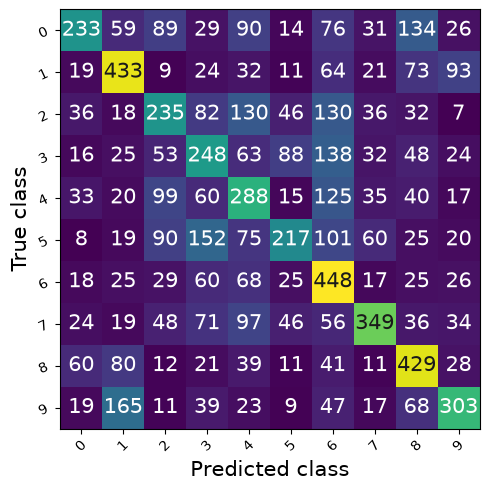

In [27]:
PrintPlotMetrics(test_loader, classes_size, modelCIFAR)

### Now training CNN into CIFAR10

In [28]:
modelCNNCIFAR = ConvolutionNeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCNNCIFAR.parameters(), lr=learning_rate)

In [29]:
historyCNN, val_historyCNN = GradientDescent(train_loader, val_loader, modelCNNCIFAR, criteria, optimizer, epochs=100)

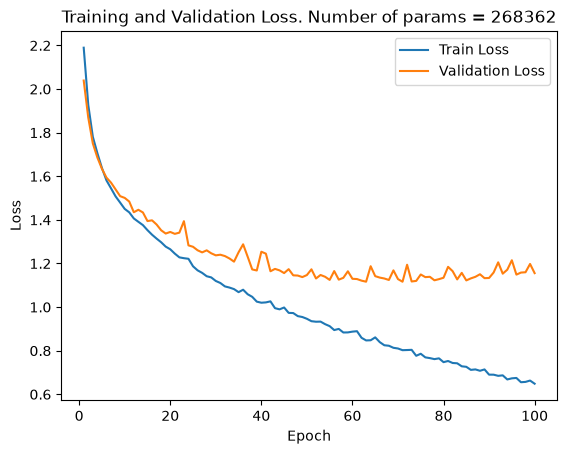

In [30]:
PlotLoss(historyCNN, val_historyCNN, modelCNNCIFAR)

Accuracy: 0.6223999857902527
F1: 0.6223999857902527
Confusion: tensor([[511,  18,  54,  36,  29,  10,  11,  19,  57,  36],
        [ 31, 562,   8,  17,   8,   4,  18,  15,  19,  97],
        [ 60,   4, 347,  75, 106,  49,  54,  42,  13,   2],
        [ 25,  11,  52, 353,  58, 106,  52,  48,  13,  17],
        [ 24,   5,  46,  55, 439,  28,  40,  65,  12,  18],
        [ 19,   9,  60, 160,  37, 364,  31,  75,   6,   6],
        [ 10,  11,  32,  86,  45,  17, 506,  11,  10,  13],
        [ 15,   5,  30,  55,  65,  44,   6, 542,   8,  10],
        [ 75,  36,  16,  25,  19,   8,  11,   3, 489,  50],
        [ 21,  44,   4,  20,   2,   7,   9,  15,  24, 555]], device='cuda:0')
Precision: 0.6223999857902527
Recall: 0.6223999857902527
Specificity: 0.9580444693565369
AUC: 0.926586925983429


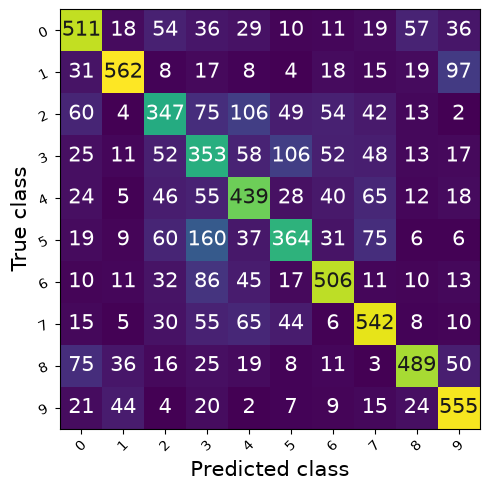

In [31]:
PrintPlotMetrics(test_loader, classes_size, modelCNNCIFAR)

## Treinamento com modificações nas imagens
Nessa seção iremos modificar as imagens e realizar o treinamento nas imagens modificadas para verificar o impacto no modelo. Usaremos o dataset do MNIST

In [84]:
# Realizando modificações nas imagens do dataset

data_transform = transforms.Compose([
    transforms.ToTensor(),
    # Rotação aleatória de até 30 graus
    transforms.RandomRotation(degrees=30),
    # zoom aleatório
    transforms.RandomResizedCrop(size=(28, 28), scale=(0.7, 1.1)),

	# Borramento (gaussian blur)
	transforms.GaussianBlur(kernel_size=(3,3), sigma=(0.1, 1.5)),

	# ruido gaussiano (função nomeada, para ser "picklable" pelos workers do DataLoader)
    transforms.Lambda(gaussian_noise)
    
])
# Downloading MNIST
dataset = tMNIST.MNIST(
    "./data",
    train=True,
    download=True,
    transform=data_transform,
)

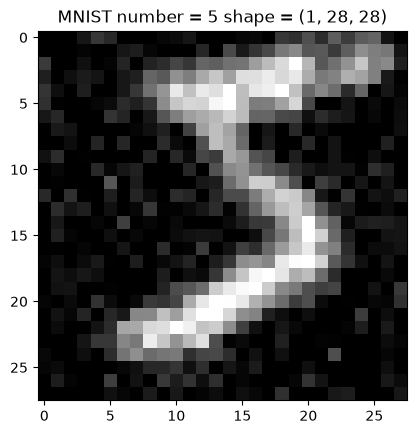

In [83]:
# Showing MNIST dataset
image, target = dataset[0]
input_size_flatten = image.numel()
classes_size = len(dataset.classes)
plt.title(f"MNIST number = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy(), cmap='gray')

In [73]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(dataset, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
# mais workers ajudam pois o gargalo é a augmentation na CPU, nao o forward/backward na GPU
num_workers = min(8, os.cpu_count() or 1) if device.type == "cuda" else 0
prefetch_factor = 4 if num_workers > 0 else None

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0, prefetch_factor=prefetch_factor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0, prefetch_factor=prefetch_factor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0, prefetch_factor=prefetch_factor)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}, Num workers: {num_workers}")

Train size: 42000, Validation size: 9000, Test size: 9000
Batch size: 1024, Pin memory: True, Num workers: 8


## NN
Testando na rede neural

In [61]:
model = NeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [62]:
history, val_history = GradientDescent(train_loader, val_loader, model, criteria, optimizer, epochs=100)

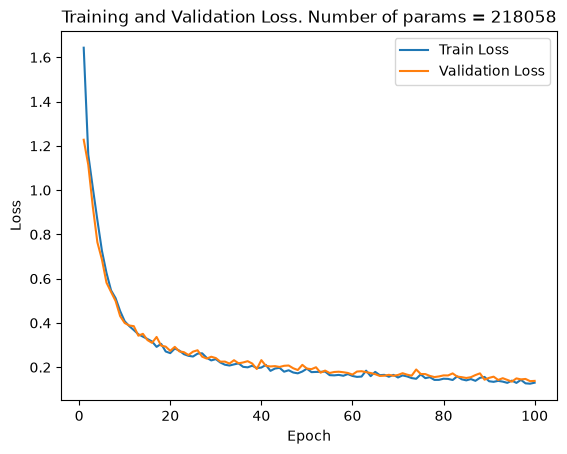

In [63]:
PlotLoss(history, val_history, model)

Accuracy: 0.9629999995231628
F1: 0.9629999995231628
Confusion: tensor([[ 897,    0,    0,    1,    1,    1,    2,    1,    2,    2],
        [   0, 1002,    1,    2,    1,    1,    0,    2,    2,    1],
        [   0,    6,  864,   10,    3,    1,    2,   16,    5,    1],
        [   0,    2,    7,  916,    0,   15,    0,    2,    6,    9],
        [   0,    2,    6,    0,  826,    0,    5,    2,    2,   29],
        [   0,    1,    2,   10,    3,  793,   12,    0,    5,    4],
        [   2,    2,    0,    0,    5,    6,  871,    0,    2,    0],
        [   0,    3,    9,    2,    7,    3,    0,  839,    1,   12],
        [   3,    3,    7,   12,    3,    4,    2,    2,  807,    9],
        [   5,    1,    1,    4,   18,    4,    1,    9,    3,  852]],
       device='cuda:0')
Precision: 0.9629999995231628
Recall: 0.9629999995231628
Specificity: 0.995888888835907
AUC: 0.9987856149673462


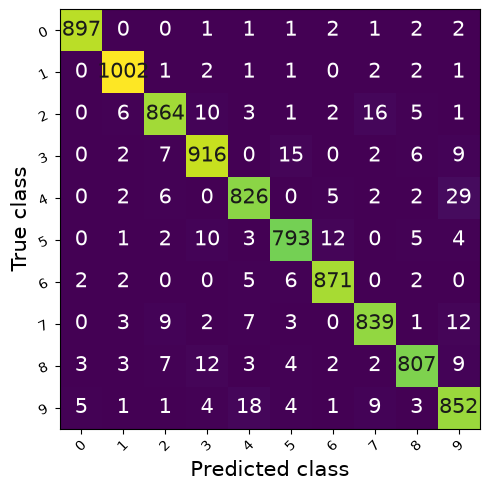

In [64]:
PrintPlotMetrics(test_loader, classes_size, model)

## CNN
Testando na CNN

In [76]:
modelCNN = ConvolutionNeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCNN.parameters(), lr=learning_rate)

In [77]:
historyCNN, val_historyCNN = GradientDescent(train_loader, val_loader, modelCNN, criteria, optimizer, epochs=100)

Epoch 1/100 - train_loss: 1.6913 - val_loss: 1.1458 - 32.3s
Epoch 2/100 - train_loss: 1.0209 - val_loss: 0.9141 - 4.6s
Epoch 3/100 - train_loss: 0.7331 - val_loss: 0.6735 - 4.5s
Epoch 4/100 - train_loss: 0.5239 - val_loss: 0.4326 - 4.6s
Epoch 5/100 - train_loss: 0.3904 - val_loss: 0.3601 - 5.0s
Epoch 6/100 - train_loss: 0.3431 - val_loss: 0.3247 - 4.9s
Epoch 7/100 - train_loss: 0.3058 - val_loss: 0.3032 - 4.9s
Epoch 8/100 - train_loss: 0.2801 - val_loss: 0.2985 - 4.8s
Epoch 9/100 - train_loss: 0.2697 - val_loss: 0.2577 - 4.8s
Epoch 10/100 - train_loss: 0.2419 - val_loss: 0.2719 - 4.9s
Epoch 11/100 - train_loss: 0.2357 - val_loss: 0.2826 - 4.8s
Epoch 12/100 - train_loss: 0.2317 - val_loss: 0.2344 - 4.9s
Epoch 13/100 - train_loss: 0.2310 - val_loss: 0.2259 - 5.3s
Epoch 14/100 - train_loss: 0.2084 - val_loss: 0.2126 - 5.0s
Epoch 15/100 - train_loss: 0.2004 - val_loss: 0.2058 - 4.9s
Epoch 16/100 - train_loss: 0.1851 - val_loss: 0.1865 - 5.0s
Epoch 17/100 - train_loss: 0.1896 - val_loss: 0.

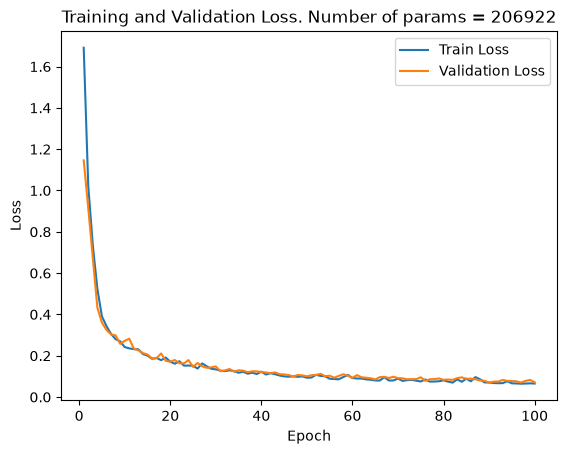

In [78]:
PlotLoss(historyCNN, val_historyCNN, modelCNN)

Accuracy: 0.9777777791023254
F1: 0.9777777791023254
Confusion: tensor([[ 901,    0,    1,    1,    0,    0,    2,    0,    1,    1],
        [   0, 1003,    3,    0,    1,    0,    0,    5,    0,    0],
        [   0,    7,  890,    1,    1,    0,    0,    6,    3,    0],
        [   1,    0,    2,  945,    0,    2,    0,    5,    1,    1],
        [   1,    0,    2,    0,  850,    2,    2,    3,    3,    9],
        [   1,    1,    2,    8,    2,  802,    8,    0,    5,    1],
        [   3,    2,    1,    1,    1,    2,  875,    0,    3,    0],
        [   0,    2,    8,    2,    4,    1,    0,  853,    1,    5],
        [   7,    5,   10,    3,    2,    2,    2,    1,  816,    4],
        [   5,    1,    1,    4,    8,    4,    0,    5,    5,  865]],
       device='cuda:0')
Precision: 0.9777777791023254
Recall: 0.9777777791023254
Specificity: 0.9975308775901794
AUC: 0.9995210766792297


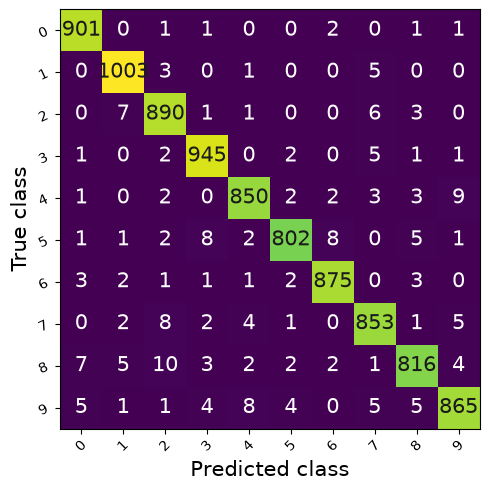

In [79]:
PrintPlotMetrics(test_loader, classes_size, modelCNN)

## Reduzindo a quantidade de exemplos por classe
No seguinte experimento utilizaremos apenas 100 exemplos por classe para realizar o treinamento dos nosso modelos e ver como se comportam

In [85]:
# Downloading MNIST
dataset = tMNIST.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

In [ ]:
train_share = 0.7
val_share = 0.15
test_share = 0.15
examples_per_class = 100

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_share, val_share, test_share],
    generator=torch.Generator().manual_seed(31),
)

all_targets = torch.as_tensor(dataset.targets)
train_targets = all_targets[train_dataset.indices]
selection_generator = torch.Generator().manual_seed(31)
selected_train_indices = []

for class_id in range(classes_size):
    class_positions = torch.where(train_targets == class_id)[0]
    shuffled_positions = class_positions[torch.randperm(len(class_positions), generator=selection_generator)]
    selected_train_indices.extend(
        train_dataset.indices[position]
        for position in shuffled_positions[:examples_per_class].tolist()
    )

train_dataset = Subset(dataset, selected_train_indices)

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
num_workers = 4 if device.type == "cuda" else 0

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory, num_workers=num_workers, persistent_workers=num_workers > 0,)
val_loader = DataLoader( val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory, num_workers=num_workers, persistent_workers=num_workers > 0,)
test_loader = DataLoader( test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory, num_workers=num_workers, persistent_workers=num_workers > 0,)

class_counts = torch.bincount(all_targets[train_dataset.indices], minlength=classes_size)
print(f"Train size: {len(train_dataset)}")
print(f"Examples per class in train: {class_counts.tolist()}")
print(f"Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")

Train size: 1000
Examples per class in train: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Validation size: 9000, Test size: 9000


In [89]:
# Treinamento da NN com poucos dados
model = NeuralNetwork(input_size_flatten, classes_size).to(device)
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
history, val_history = GradientDescent(
    train_loader, val_loader, model, criteria, optimizer, epochs=100
)

Epoch 1/100 - train_loss: 2.3068 - val_loss: 2.2788 - 7.1s
Epoch 2/100 - train_loss: 2.2758 - val_loss: 2.2499 - 0.2s
Epoch 3/100 - train_loss: 2.2451 - val_loss: 2.2129 - 0.2s
Epoch 4/100 - train_loss: 2.2063 - val_loss: 2.1677 - 0.2s
Epoch 5/100 - train_loss: 2.1592 - val_loss: 2.1156 - 0.2s
Epoch 6/100 - train_loss: 2.1048 - val_loss: 2.0573 - 0.2s
Epoch 7/100 - train_loss: 2.0442 - val_loss: 1.9928 - 0.2s
Epoch 8/100 - train_loss: 1.9771 - val_loss: 1.9222 - 0.2s
Epoch 9/100 - train_loss: 1.9038 - val_loss: 1.8463 - 0.3s
Epoch 10/100 - train_loss: 1.8250 - val_loss: 1.7664 - 0.2s
Epoch 11/100 - train_loss: 1.7417 - val_loss: 1.6836 - 0.2s
Epoch 12/100 - train_loss: 1.6552 - val_loss: 1.5986 - 0.2s
Epoch 13/100 - train_loss: 1.5665 - val_loss: 1.5124 - 0.2s
Epoch 14/100 - train_loss: 1.4764 - val_loss: 1.4261 - 0.2s
Epoch 15/100 - train_loss: 1.3862 - val_loss: 1.3413 - 0.2s
Epoch 16/100 - train_loss: 1.2975 - val_loss: 1.2592 - 0.2s
Epoch 17/100 - train_loss: 1.2115 - val_loss: 1.1

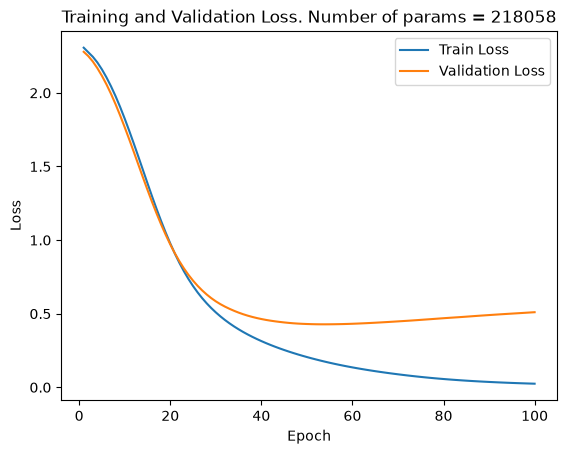

In [90]:
PlotLoss(history, val_history, model)

Accuracy: 0.8761110901832581
F1: 0.8761110901832581
Confusion: tensor([[870,   0,   6,   5,   2,  14,   6,   2,   2,   0],
        [  0, 935,   4,  14,   3,   6,   2,   7,  41,   0],
        [  9,   7, 793,  25,  13,   3,  23,  11,  22,   2],
        [  5,   2,  44, 788,   4,  39,   2,  11,  45,  17],
        [  5,   1,  10,   3, 799,   6,   8,   0,   1,  39],
        [ 19,   6,  13,  37,  12, 667,  16,   5,  43,  12],
        [ 15,   0,   4,   2,   8,  21, 833,   0,   5,   0],
        [  5,   9,  13,  13,  24,   2,   1, 764,   7,  38],
        [  9,  10,  24,  49,  13,  56,   6,   5, 656,  24],
        [ 17,   0,  11,   7,  30,   8,   0,  28,  17, 780]], device='cuda:0')
Precision: 0.8761110901832581
Recall: 0.8761110901832581
Specificity: 0.9862345457077026
AUC: 0.9863477945327759


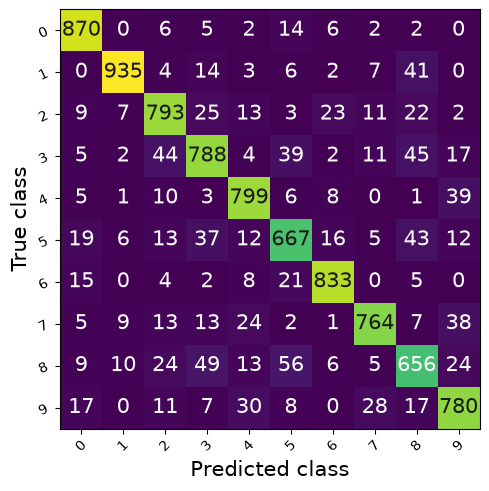

In [91]:
PrintPlotMetrics(test_loader, classes_size, model)

In [ ]:
modelCNN = ConvolutionNeuralNetwork(input_size_flatten, classes_size).to(device)
optimizer = optim.Adam(modelCNN.parameters(), lr=0.001)
historyCNN, val_historyCNN = GradientDescent(
    train_loader, val_loader, modelCNN, criteria, optimizer, epochs=100
)

Epoch 1/100 - train_loss: 2.3032 - val_loss: 2.2695 - 0.9s
Epoch 2/100 - train_loss: 2.2669 - val_loss: 2.2294 - 0.2s
Epoch 3/100 - train_loss: 2.2250 - val_loss: 2.1776 - 0.2s
Epoch 4/100 - train_loss: 2.1718 - val_loss: 2.1144 - 0.2s
Epoch 5/100 - train_loss: 2.1070 - val_loss: 2.0385 - 0.2s
Epoch 6/100 - train_loss: 2.0293 - val_loss: 1.9505 - 0.2s
Epoch 7/100 - train_loss: 1.9389 - val_loss: 1.8514 - 0.2s
Epoch 8/100 - train_loss: 1.8368 - val_loss: 1.7423 - 0.2s
Epoch 9/100 - train_loss: 1.7245 - val_loss: 1.6253 - 0.2s
Epoch 10/100 - train_loss: 1.6040 - val_loss: 1.5021 - 0.2s
Epoch 11/100 - train_loss: 1.4776 - val_loss: 1.3771 - 0.2s
Epoch 12/100 - train_loss: 1.3497 - val_loss: 1.2540 - 0.2s
Epoch 13/100 - train_loss: 1.2236 - val_loss: 1.1372 - 0.2s
Epoch 14/100 - train_loss: 1.1034 - val_loss: 1.0308 - 0.2s
Epoch 15/100 - train_loss: 0.9928 - val_loss: 0.9365 - 0.2s
Epoch 16/100 - train_loss: 0.8942 - val_loss: 0.8542 - 0.2s
Epoch 17/100 - train_loss: 0.8079 - val_loss: 0.7

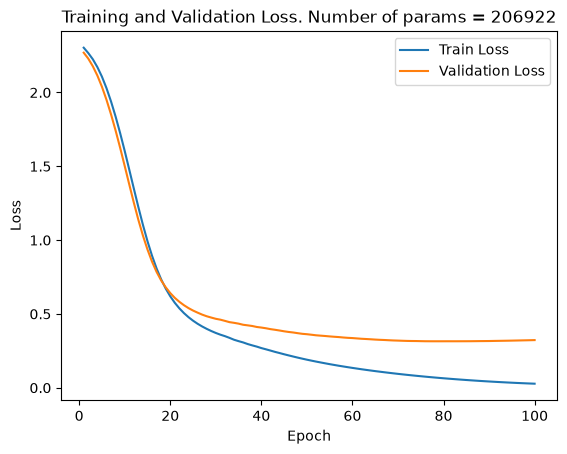

In [93]:
PlotLoss(historyCNN, val_historyCNN, modelCNN)

Accuracy: 0.9231111407279968
F1: 0.9231111407279968
Confusion: tensor([[884,   0,   3,   1,   2,   7,   2,   6,   2,   0],
        [  0, 953,   6,   4,   5,   1,   3,   6,  34,   0],
        [  5,   3, 839,  12,  11,   2,   5,  16,  14,   1],
        [  3,   2,  24, 870,   1,  12,   0,   5,  26,  14],
        [  1,   1,  15,   3, 811,   2,   1,   4,   2,  32],
        [  3,   2,   3,  15,   3, 774,  16,   1,   8,   5],
        [  6,   0,   2,   0,   9,  18, 851,   1,   1,   0],
        [ 11,   2,  12,   9,  14,   5,   0, 790,   2,  31],
        [ 11,   4,  12,  27,   3,  30,   8,   4, 736,  17],
        [ 12,   0,  12,   7,  13,  13,   0,  29,  12, 800]], device='cuda:0')
Precision: 0.9231111407279968
Recall: 0.9231111407279968
Specificity: 0.9914568066596985
AUC: 0.9947181940078735


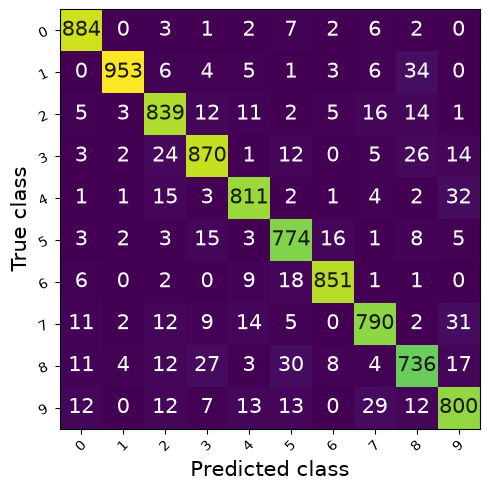

In [94]:
PrintPlotMetrics(test_loader, classes_size, modelCNN)